# 07 The LLM layer: what ran, what did not, and the RAG gates

Everything here ran **offline against deterministic stubs**. No live model was used (no API key is configured), so there are no live accuracy numbers; they are marked pending.
The layer has three parts: sandboxed text-to-SQL over DuckDB marts (structured data, so not RAG), building biographies with citations and a code-based verifier, and two measured gates deciding whether retrieval (RAG) earns a place. Write-up: [`docs/llm_layer.md`](../docs/llm_layer.md).

In [1]:
from nbutil import *
import json
h = json.loads((REPORTS / "phase7" / "llm_harness.json").read_text())
print(h["mode"])
pd.DataFrame(h["text_to_sql"]).T.round(3)

harness (deterministic stubs, NOT model results)


,execution_accuracy,executable,n
stub-oracle,1.000,1.0,58.0
stub-wrong,0.000,1.0,58.0
stub-keyword,0.034,1.0,58.0


The three stubs bracket the metric: the oracle stub (returns the reference SQL) must score 1.0, an always-`SELECT 1` stub 0.0, and a crude keyword stub 0.03. They show the harness can fail and say **nothing** about how well a language model writes SQL.

For biographies, the verifier is code, not a model: cited ids must exist, numbers must appear in a cited record, no uncited factual sentence, no blame language.

In [2]:
b = h["biography"]
print(f"template biographies passing the verifier: {b['template_fully_verified']}/{b['buildings']}")
print(f"numeric corruptions caught: {b['numeric_corruptions_caught']}/{b['numeric_corruptions_tried']}; invented ids caught: {b['invented_ids_caught']}/{b['numeric_corruptions_tried']}")

template biographies passing the verifier: 40/40
numeric corruptions caught: 40/40; invented ids caught: 40/40


## Gate E1: does retrieval beat plain SQL keywords at finding the records about a condition?

Within one building's violation records, retrieve those about a condition ("no heat or hot water", "rats mice and roaches", ...). Ground truth is structured (HPD order-number families), independent of the text. 400 buildings, 2,317 building-condition pairs.
Rule fixed in advance: adopt retrieval only if BM25 beats the SQL keyword baseline by at least 0.03 precision@10 with the paired interval above 0.

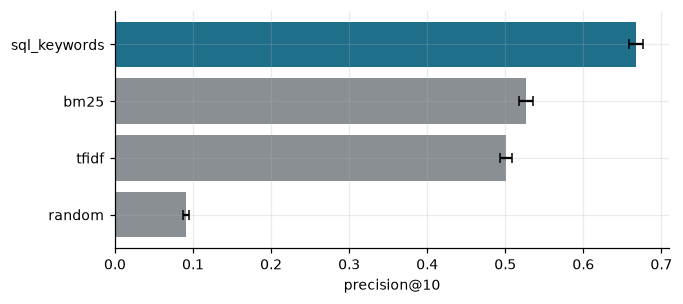

In [3]:
r = json.loads((REPORTS / "phase7" / "retrieval_eval.json").read_text())["summary"]
names = ["sql_keywords", "bm25", "tfidf", "random"]
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.barh(names[::-1], [r[n]["precision_at_10"] for n in names][::-1], xerr=[[r[n]["precision_at_10"] - r[n]["p_lo"] for n in names][::-1], [r[n]["p_hi"] - r[n]["precision_at_10"] for n in names][::-1]], color=[GREY, GREY, GREY, BLUE], capsize=3)
ax.set_xlabel("precision@10"); plt.show()

Plain SQL keywords win (0.67 vs BM25 0.53). Retrieval wins only on lead paint. **Not adopted.** Caveat: the keyword lists were written by someone who knew the corpus vocabulary, which is what a SQL user with domain knowledge does; an embedding model was not tried.

## Gate E2: do text-derived severity features improve the Phase 3 model?

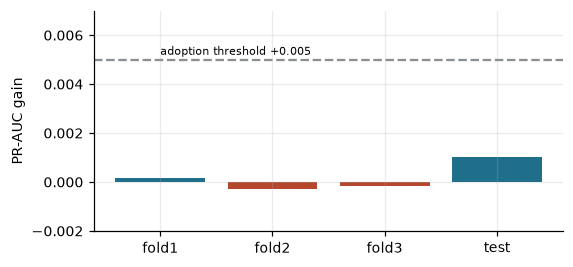

,fold,pr_auc_base,pr_auc_text,gain
0,fold1,0.6255,0.6257,0.0002
1,fold2,0.6533,0.6530,-0.0003
2,fold3,0.6603,0.6601,-0.0002
3,test,0.6450,0.6460,0.0010


In [4]:
t = pd.DataFrame(json.loads((REPORTS / "phase7" / "text_features_eval.json").read_text())["rows"])
x = t[t.target == "label_serious_any"]
fig, ax = plt.subplots(figsize=(5.5, 2.6)); ax.bar(x.fold, x.gain, color=[BLUE if g > 0 else RED for g in x.gain]); ax.axhline(0.005, color=GREY, ls="--"); ax.text(0, 0.0052, "adoption threshold +0.005", fontsize=7)
ax.set_ylabel("PR-AUC gain"); ax.set_ylim(-0.002, 0.007); plt.show()
x[["fold", "pr_auc_base", "pr_auc_text", "gain"]].round(4)

The gain is detectable but negligible (about +0.001 PR-AUC, positive in 2 of 4 folds), far below the +0.005 threshold. **Not adopted.**

## Conclusion
RAG is not used anywhere in the pipeline, by measurement: the two places where it might have helped were tested against a simple baseline and lost. The text-to-SQL and biography components stand on their own and are ready for a live evaluation (`make llm-live`, needs an API key).
